# Unidad 1: Vectores, Matrices y Tensores

## Matemáticas para Análisis de Datos — ITEC

**Objetivos de esta notebook:**
- Crear y manipular arrays 1D (vectores), 2D (matrices) y 3D+ (tensores) con NumPy
- Entender los atributos `shape`, `size`, `ndim` y `dtype`
- Aplicar indexación, slicing y transformaciones estructurales
- Visualizar los datos como estructuras matemáticas

---
**Dataset del curso:** precios de casas con features: `size_m2`, `rooms`, `distance_km`, `price_usd`

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f"NumPy version: {np.__version__}")

NumPy version: 2.4.2


## 1. Vectores — Arrays 1D: una sola observación

Un **vector** es una secuencia ordenada de números. En nuestro dataset, cada casa es un vector de features.

```
casa_1 = [size_m2=120, rooms=3, distance_km=2.5, price_usd=180000]
```

In [12]:
casa_1 = np.array([120.0, 3.0, 2.5, 180000.0])

print("Vector (casa 1):", casa_1)
print("Tipo de objeto:", type(casa_1))
print("shape:", casa_1.shape)    # (4,) → un eje con 4 elementos
print("size:", casa_1.size)      # 4 elementos totales
print("ndim:", casa_1.ndim)      # 1 dimensión
print("dtype:", casa_1.dtype)    # float64

Vector (casa 1): [   120.       3.       2.5 180000. ]
Tipo de objeto: <class 'numpy.ndarray'>
shape: (4,)
size: 4
ndim: 1
dtype: float64


In [3]:
# Acceder a elementos del vector
print("Tamaño:", casa_1[0], "m²")
print("Habitaciones:", casa_1[1])
print("Distancia al centro:", casa_1[2], "km")
print("Precio:", casa_1[3], "USD")
print("Último elemento:", casa_1[-1])   # indexación negativa

Tamaño: 120.0 m²
Habitaciones: 3.0
Distancia al centro: 2.5 km
Precio: 180000.0 USD
Último elemento: 180000.0


## 2. Matrices — Arrays 2D: el dataset completo

Una **matriz** organiza múltiples observaciones. Cada **fila** es una casa, cada **columna** es una feature.

| | size_m2 | rooms | distance_km | price_usd |
|---|---|---|---|---|
| casa 0 | 120 | 3 | 2.5 | 180000 |
| casa 1 | 85 | 2 | 1.0 | 150000 |
| casa 2 | 200 | 4 | 5.0 | 250000 |
| casa 3 | 60 | 1 | 0.5 | 120000 |
| casa 4 | 150 | 3 | 3.2 | 210000 |

In [6]:
np.set_printoptions(suppress=True, precision=2)

dataset = np.array([
    [120.0,  3.0,  2.5, 180000.0],
    [ 85.0,  2.0,  1.0, 150000.0],
    [200.0,  4.0,  5.0, 250000.0],
    [ 60.0,  1.0,  0.5, 120000.0],
    [150.0,  3.0,  3.2, 210000.0]
])

print("Dataset:\n", dataset)
print("\nshape:", dataset.shape)   # (5, 4) → 5 filas, 4 columnas
print("ndim:", dataset.ndim)       # 2 dimensiones
print("size:", dataset.size)       # 20 elementos totales

Dataset:
 [[   120.       3.       2.5 180000. ]
 [    85.       2.       1.  150000. ]
 [   200.       4.       5.  250000. ]
 [    60.       1.       0.5 120000. ]
 [   150.       3.       3.2 210000. ]]

shape: (5, 4)
ndim: 2
size: 20


In [26]:
# Indexación sobre matrices
print("Primera casa (fila 0):", dataset[0])
print("Tercera casa (fila 2):", dataset[2])
print("Precios (columna 3):", dataset[:, 3])        # todos los precios
print("Tamaños (columna 0):", dataset[:, 0])        # todos los tamaños
print("\nPrimeras 3 casas:\n", dataset[0:3, :])     # slicing de filas
print("\nSolo features (sin precio):\n", dataset[:, 0:3])

Primera casa (fila 0): [   120.       3.       2.5 180000. ]
Tercera casa (fila 2): [   200.      4.      5. 250000.]
Precios (columna 3): [180000. 150000. 250000. 120000. 210000.]
Tamaños (columna 0): [120.  85. 200.  60. 150.]

Primeras 3 casas:
 [[   120.       3.       2.5 180000. ]
 [    85.       2.       1.  150000. ]
 [   200.       4.       5.  250000. ]]

Solo features (sin precio):
 [[120.    3.    2.5]
 [ 85.    2.    1. ]
 [200.    4.    5. ]
 [ 60.    1.    0.5]
 [150.    3.    3.2]]


In [8]:
# Convención estándar en ML: separar X (features) de y (target)
X = dataset[:, 0:3]   # size_m2, rooms, distance_km
y = dataset[:, 3]     # price_usd

print("X (features) shape:", X.shape)   # (5, 3)
print("y (precios) shape:", y.shape)    # (5,)

X (features) shape: (5, 3)
y (precios) shape: (5,)


## 3. Tensores — Arrays 3D+: más dimensiones

Un tensor generaliza matrices a más dimensiones.

**Ejemplo:** 3 imágenes en escala de grises de 4×4 píxeles.

```
shape: (3, 4, 4)  →  3 imágenes × 4 filas × 4 columnas
```

In [30]:
np.random.seed(42)
imagenes = np.random.randint(0, 256, size=(3, 4, 4))

print("shape:", imagenes.shape)    # (3, 4, 4)
print("ndim:", imagenes.ndim)
print("dtype:", imagenes.dtype)
print("size:", imagenes.size)      # 3
print("\nPrimera imagen (índice 0):\n", imagenes[0])
print("\nSegunda imagen (índice 1):\n", imagenes[1])

shape: (3, 4, 4)
ndim: 3
dtype: int64
size: 48

Primera imagen (índice 0):
 [[102 179  92  14]
 [106  71 188  20]
 [102 121 210 214]
 [ 74 202  87 116]]

Segunda imagen (índice 1):
 [[ 99 103 151 130]
 [149  52   1  87]
 [235 157  37 129]
 [191 187  20 160]]


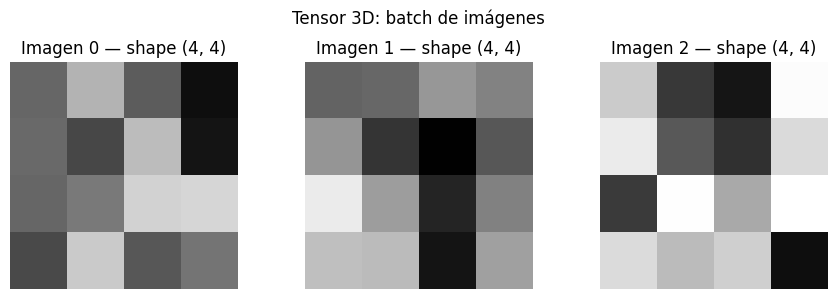

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for i, ax in enumerate(axes):
    ax.imshow(imagenes[i], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Imagen {i} — shape {imagenes[i].shape}')
    ax.axis('off')
plt.suptitle('Tensor 3D: batch de imágenes')
plt.tight_layout()
plt.show()

## 4. Reshape y Flatten: cambiar la forma sin mover datos

- **`reshape(nueva_forma)`**: reorganiza los datos en una nueva forma (el total de elementos debe ser igual)
- **`flatten()`**: convierte cualquier array a 1D
- **`-1` en reshape**: "calculá esta dimensión automáticamente"

In [11]:
print("dataset original shape:", dataset.shape)   # (5, 4)

# Flatten: aplanar a 1D
flat = dataset.flatten()
print("después de flatten():", flat.shape)         # (20,)
print(flat)

# Reshape: volver a la forma original
restaurado = flat.reshape(5, 4)
print("\nrestaurado con reshape(5, 4):\n", restaurado)

# Usando -1: NumPy calcula la dimensión faltante
restaurado2 = flat.reshape(-1, 4)   # -1 → NumPy calcula que son 5 filas
print("\ncon reshape(-1, 4), shape:", restaurado2.shape)

dataset original shape: (5, 4)
después de flatten(): (20,)
[   120.       3.       2.5 180000.      85.       2.       1.  150000.
    200.       4.       5.  250000.      60.       1.       0.5 120000.
    150.       3.       3.2 210000. ]

restaurado con reshape(5, 4):
 [[   120.       3.       2.5 180000. ]
 [    85.       2.       1.  150000. ]
 [   200.       4.       5.  250000. ]
 [    60.       1.       0.5 120000. ]
 [   150.       3.       3.2 210000. ]]

con reshape(-1, 4), shape: (5, 4)


In [ ]:
# Caso práctico: preparar imágenes para una red neuronal densa
# La red espera vectores 1D, pero las imágenes son 2D
print("Imágenes originales shape:", imagenes.shape)     # (3, 4, 4)

imagenes_aplanadas = imagenes.reshape(3, -1)            # (3, 16)
print("Después de reshape(3, -1):", imagenes_aplanadas.shape)
print("Cada imagen es ahora un vector de", imagenes_aplanadas.shape[1], "píxeles")

## 5. Indexación booleana: filtrar datos sin loops

In [ ]:
# ¿Cuáles casas tienen más de 100 m²?
mascara = dataset[:, 0] > 100
print("Máscara booleana:", mascara)
print("\nCasas con más de 100 m²:\n", dataset[mascara])

# Casas con precio < 200000 Y tamaño > 80
baratas_y_grandes = (dataset[:, 3] < 200000) & (dataset[:, 0] > 80)
print("\nCasas baratas y grandes:\n", dataset[baratas_y_grandes])

## Ejercicios

**Ejercicio 1:** Creá un vector que represente un departamento de 55 m², 1 habitación, 0.3 km del centro y precio $95000. Imprimí su `shape` y `dtype`.

**Ejercicio 2:** Agregá ese departamento al dataset existente usando `np.vstack`. ¿Cuál es el nuevo `shape`?

**Ejercicio 3:** Calculá el precio promedio de todas las casas usando `dataset[:, 3].mean()`.

**Ejercicio 4:** Filtrá las casas cuya distancia al centro sea menor a 2 km.

In [ ]:
# Ejercicio 1
# tu código acá


In [ ]:
# Ejercicio 2
# tu código acá


In [ ]:
# Ejercicio 3 y 4
# tu código acá
